# 02 · KOFA hall layouts

**Goal:** turn Hall 1 and Hall 2 into SeatScore layouts. That means the exact seat plan (rows, aisles, wheelchair spaces, seat numbers), where row S sits, and the screen and room dimensions the scoring engine needs.

**Evidence used, from strongest to weakest:**

1. **KOFA's official seat maps and visitor guide** ([이용안내](https://www.koreafilm.or.kr/pages/PC_00000004)): row order, aisles, wheelchair spaces and screen sizes. The maps are KOFA's images and aren't reproduced here.
2. **The booking data** from notebook 01: which seat numbers are actually sold, and how often.
3. **Viewer comments** on a [muko.kr review](https://muko.kr/movietalk/5501817): qualitative notes on row S and screen height.
4. **Typical cinema dimensions** for anything not published: row spacing, first-row distance and rake. These are estimates and are labelled as such.

The layouts themselves are defined in `pipeline/layouts.py` (tested in `pipeline/test_layouts.py`). This notebook checks them and writes them to the web app.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from pipeline.kofa import DISTANCING, WHEELCHAIR_ROW
from pipeline.layouts import HALL1, HALL2, HALL_IDS, aisle_seat_ids, seat_ids, write_web_layouts

INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

seats = pd.read_csv("../processed/kofa_seat_bookings.csv.gz", parse_dates=["showtime"])
LAYOUT = {"hall1": HALL1, "hall2": HALL2}
print(f"{len(seats):,} booked seats loaded")

440,083 booked seats loaded


## 1. What the official map shows

| | Hall 1 | Hall 2 |
|---|---|---|
| Screen (official) | 12.64 × 5.40 m (2.34:1) | 8.60 × 4.65 m (1.85:1) |
| Blocks | seats 1–6 \| 7–15 \| 16–21 | seats 1–2 \| 3–10 \| 11–12 |
| Row order, screen first | A–J, **S**, K, L, M, N, O | A–M |
| Wheelchair spaces | 2 in row N (in place of seats 7–10), 2 in row O (right block) | 2 in row M (in place of seats 3–6) |
| Short rows | N: 17 seats · O: 13 drawn | L: seats 2–11 · M: seats 2 and 7–11 |

**Row S sits between rows J and K**, not at the back. The visitor guide lists 321 regular seats plus 4 wheelchair spaces for Hall 1. KOFA's rental FAQ says 317 seats, and the booking data agrees with 317 + 4.

## 2. Does the layout match the seats that are actually sold?

Compare the layout's seat ids with every seat id in nine years of bookings.

In [2]:
check = []
for hall, layout in LAYOUT.items():
    planned = set(seat_ids(layout))
    counts = seats[seats["hall"] == hall].groupby("seat_id").size()
    sold = set(counts.index)
    only_data = sorted(sold - planned)
    check.append({
        "hall": hall,
        "seats in layout": len(planned),
        "seats in bookings": len(sold),
        "in both": len(planned & sold),
        "layout only": sorted(planned - sold) or "-",
        "bookings only (times booked)": ", ".join(f"{s} ({counts[s]})" for s in only_data) or "-",
    })
pd.DataFrame(check).set_index("hall")

,seats in layout,seats in bookings,in both,layout only,bookings only (times booked)
hall,,,,,
hall1,321,326,321,-,"N8 (4), O10 (3), O7 (15), O8 (7), O9 (1)"
hall2,150,152,150,-,"M3 (7), M5 (7)"


Every seat in both layouts appears in the bookings. The only seats in the bookings but not in the layouts are a handful of ids booked a few times over nine years: N8, O7–O10 and Hall 2's M3 and M5. They sit where wheelchair spaces or unsold seats are now, so they are most likely from before a refit, or from manual bookings.

**Row O:** the map draws 13 seats, but only O1–O6 have ever been sold. O11–O17 are left out of the layout.

## 3. Booking popularity by position

From here on, the 2020–22 distancing window is excluded (notebook 01, section 8), since blocked seats would distort these numbers.

### Across the row: aisles

Average share of screenings in which each seat number is booked, across all full-width rows. Dashed lines mark the aisles from the official map.

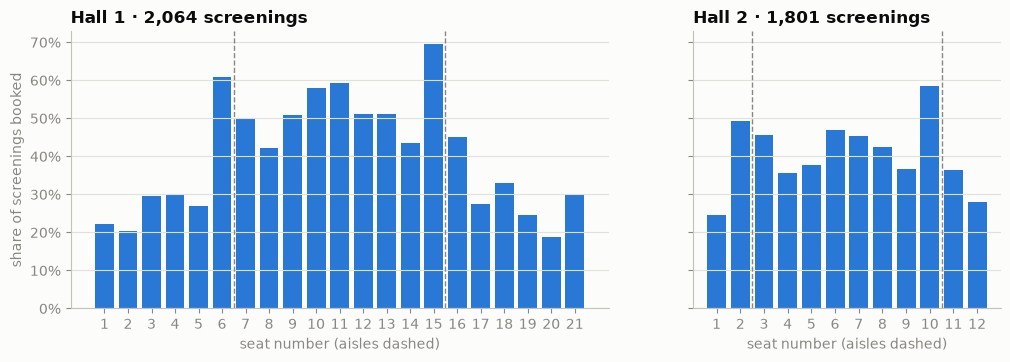

In [3]:
normal = seats[~seats["showtime"].between(*DISTANCING) & (seats["row"] != WHEELCHAIR_ROW)]
n_screenings = normal.groupby("hall")["showtime"].nunique()

def seat_rates(hall):
    h = normal[normal["hall"] == hall]
    rate = h.groupby(["row", "number"]).size() / n_screenings[hall]
    return rate.rename("rate").reset_index()

AISLES = {"hall1": [6.5, 15.5], "hall2": [2.5, 10.5]}
FULL_ROWS = {"hall1": list("ABCDEFGHIJSKLM"), "hall2": list("ABCDEFGHIJK")}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [21, 12]}, sharey=True)
for ax, hall in zip(axes, ["hall1", "hall2"]):
    r = seat_rates(hall)
    profile = r[r["row"].isin(FULL_ROWS[hall])].groupby("number")["rate"].mean()
    ax.bar(profile.index, profile.values, color=BLUE, width=0.8)
    for x in AISLES[hall]:
        ax.axvline(x, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xticks(profile.index)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel("seat number (aisles dashed)")
    ax.set_title(f"{'Hall 1' if hall == 'hall1' else 'Hall 2'} · {n_screenings[hall]:,} screenings", loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("share of screenings booked")
plt.show()

In [4]:
rows_out = []
for hall, layout in LAYOUT.items():
    aisle = aisle_seat_ids(layout)
    r = seat_rates(hall)
    r = r[r["row"].isin(FULL_ROWS[hall])]
    r["seat_id"] = r["row"] + r["number"].astype(str)
    r["wall_end"] = r["number"].isin([1, r["number"].max()])
    r["position"] = np.where(r["wall_end"], "wall end", np.where(r["seat_id"].isin(aisle), "beside an aisle", "inside a block"))
    summary = r.groupby("position")["rate"].agg(["mean", "size"]).rename(columns={"mean": "booking rate", "size": "seats"})
    summary["booking rate"] = summary["booking rate"].map("{:.0%}".format)
    rows_out.append(summary.assign(hall=hall).set_index("hall", append=True).swaplevel())
pd.concat(rows_out)

booking rate  seats
hall  position                           
hall1 beside an aisle          56%     56
      inside a block           38%    210
      wall end                 26%     28
hall2 beside an aisle          47%     44
      inside a block           41%     66
      wall end                 26%     22

**Seats beside the inner aisles are booked more than seats inside a block:** 56% vs 38% in Hall 1, and 47% vs 41% in Hall 2. Seats against the wall are booked least (26% in both halls), even though SeatScore's model also treats them as aisle seats, because they're as far off-center as a seat can be.

**The effect is lopsided.** In both halls the standout seat is the one just *before* each aisle in seat-number order. In Hall 1, seat 6 is booked 61% of the time and seat 15 is booked 70%, versus 50% and 45% for seats 7 and 16 across the aisle. In Hall 2, seat 2 is booked 49% and seat 10 is booked 58%, versus 46% and 36% for seats 3 and 11. The data can't say why. It could be the side people enter from, or which seats the booking page suggests first. It's worth keeping in mind before reading too much into one aisle.

For notebook 03, this means **aisle access matters to real viewers**, but only when the seat is also fairly central.

### Front to back: row S

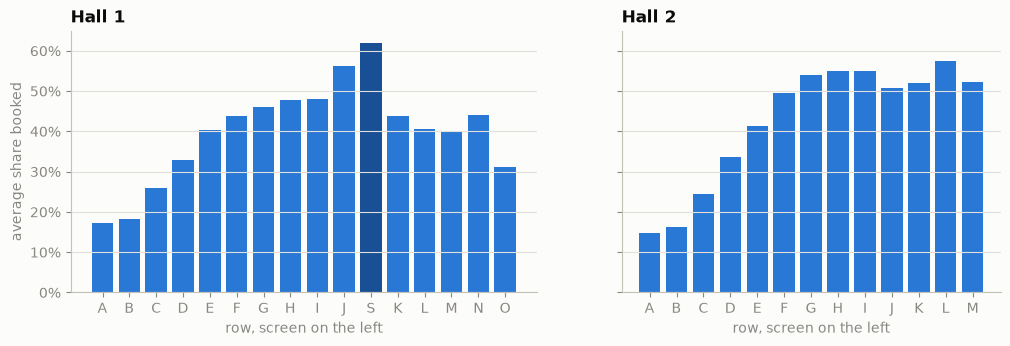

row,A,B,C,D,E,F,G,H,I,J,S,K,L,M,N,O
Hall 1 average booking rate,17%,18%,26%,33%,40%,44%,46%,48%,48%,56%,62%,44%,41%,40%,44%,31%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [16, 13]}, sharey=True)
for ax, hall in zip(axes, ["hall1", "hall2"]):
    r = seat_rates(hall)
    order = [row["label"] for row in LAYOUT[hall]["rows"]]
    profile = r.groupby("row")["rate"].mean().reindex(order)
    colors = [BLUE if row != "S" else "#184f95" for row in order]
    ax.bar(order, profile.values, color=colors, width=0.8)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel("row, screen on the left")
    ax.set_title("Hall 1" if hall == "hall1" else "Hall 2", loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("average share booked")
plt.show()

h1 = seat_rates("hall1").groupby("row")["rate"].mean().reindex([row["label"] for row in HALL1["rows"]])
h1.map("{:.0%}".format).to_frame("Hall 1 average booking rate").T

In Hall 1, booking rises from the front rows to a peak at rows J and S, and **row S is the single most-booked row (62%).** That fits the map, which puts S right after J, and the viewer comments: S has open space in front of it and a big step up, so nobody's head is in the way and there's legroom. The layout models S with a **1.0 m cross aisle in front** and an **extra 0.35 m step**. Both numbers are estimates.

## 4. Room dimensions

Only the screens and seat plans are published. Everything else is estimated:

| Value | Hall 1 | Hall 2 | Basis |
|---|---|---|---|
| Screen width × height | 12.64 × 5.40 m | 8.60 × 4.65 m | **Official** |
| Seat width | 0.55 m | 0.55 m | Typical cinema seat pitch. In Hall 1, 23 columns × 0.55 m = 12.65 m, the same as the screen width, which fits a room as wide as its screen |
| Row spacing | 1.00 m | 0.95 m | Typical for fixed seats (0.95–1.10 m) |
| First row distance | 5.0 m | 4.0 m | Typical: front row at roughly 0.4–0.5 × screen width |
| Screen bottom height | 1.5 m | 1.2 m | Reviews say the screen sits high and front rows strain the neck |
| Rake (rise per row) | 0.15 m | 0.15 m | Typical for a sloped floor without stadium risers |
| Row S | +1.0 m gap, +0.35 m step | – | Cross aisle and a large step (from viewer comments) |

The cell below works out what these numbers imply row by row, using the same formulas as SeatScore's engine. That's a quick check that the estimates give plausible viewing angles.

In [6]:
EYE = 1.12  # seated eye height, same as the engine

def row_geometry(layout):
    out, extra_d, extra_rise = [], 0.0, 0.0
    sc = layout["screen"]
    for i, row in enumerate(layout["rows"]):
        extra_d += row.get("gapBeforeM", 0)
        extra_rise += row.get("stepM", 0)
        d = layout["firstRowM"] + i * layout["rowSpacingM"] + extra_d
        eye = (i + 1) * layout["rake"]["riserM"] + extra_rise + EYE
        center = sc["bottomM"] + sc["heightM"] / 2
        out.append({
            "row": row["label"],
            "distance (m)": round(d, 1),
            "screen fills (°)": round(np.degrees(2 * np.arctan(sc["widthM"] / 2 / d))),
            "look up to center (°)": round(np.degrees(np.arctan((center - eye) / d))),
        })
    return pd.DataFrame(out).set_index("row").T

display(row_geometry(HALL1))
display(row_geometry(HALL2))

row,A,B,C,D,E,F,G,H,I,J,S,K,L,M,N,O
distance (m),5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,16.0,17.0,18.0,19.0,20.0,21.0
screen fills (°),103.0,93.0,84.0,77.0,70.0,65.0,60.0,56.0,52.0,49.0,43.0,41.0,39.0,37.0,35.0,33.0
look up to center (°),30.0,25.0,21.0,17.0,15.0,12.0,10.0,9.0,8.0,6.0,4.0,3.0,2.0,2.0,1.0,1.0


row,A,B,C,D,E,F,G,H,I,J,K,L,M
distance (m),4.0,5.0,5.9,6.8,7.8,8.8,9.7,10.6,11.6,12.5,13.5,14.4,15.4
screen fills (°),94.0,82.0,72.0,64.0,58.0,52.0,48.0,44.0,41.0,38.0,35.0,33.0,31.0
look up to center (°),29.0,23.0,18.0,15.0,12.0,10.0,8.0,6.0,5.0,4.0,3.0,2.0,2.0


With these estimates, Hall 1's front row looks up about 30° to the picture center, which matches the neck-strain comments. The screen fills 40° of view at rows K–L, one or two rows behind the booking peak at J and S (43–49°). Either viewers like a slightly bigger picture than the 40° default, or the first-row estimate is a little short. Hall 2 reaches 40° around row I, while its bookings stay high all the way back to L and M.

These numbers drive the scores directly, so they are the first thing to tighten if a measured plan turns up. Notebook 03 will also test how sensitive the comparison is to them.

## 5. Write the layouts to the web app

In [7]:
path = write_web_layouts()
print("wrote", path.relative_to(Path.cwd().parents[1]))

wrote web/src/data/kofa_layouts.json


## Findings

1. **Seat plans confirmed:** both layouts match the official maps and the seats actually sold. That's 321 positions in Hall 1 (317 seats + 4 wheelchair spaces) and 150 in Hall 2 (148 + 2).
2. **Row S** is between J and K, behind a cross aisle, and it's Hall 1's most-booked row.
3. **Aisles:** Hall 1 is split 1–6 | 7–15 | 16–21, and Hall 2 is split 1–2 | 3–10 | 11–12. Seats beside the inner aisles are booked more than seats inside a block (56% vs 38% in Hall 1, 47% vs 41% in Hall 2), and the seat just before each aisle in number order leads. Wall-end seats are the least booked.
5. **Picture size:** the booking peak sits where the screen fills about 43–49° (Hall 1), a little wider than SeatScore's 40° default.
4. **Dimensions:** screen sizes are official. Row spacing, first-row distance, screen height and rake are typical-value estimates, listed in each layout's `sources`.

**Next (`03_preference`):** compare SeatScore's geometry ranking with these booking rates and with booking order, excluding the distancing window, and see which weights fit real behavior best.